## Business Intelligence - Lab 4: Clustering Analysis
### Task: Descriptive Analysis, Unsupervised Learning - EV Charging Network Expansion

##### Group: 26
##### Student Names: Al Amin Alif, Md Rakib Uddin


## Public version note

Prepared for publication in November 2026 from the original Group 26 coursework. Original author names and group context are retained; university email addresses are omitted. Setup and compatibility changes are listed in PUBLICATION_NOTES.md. Outputs in this version are regenerated during verification.

The clusters describe a small teaching dataset. Choosing k using silhouette scores is exploratory, not evidence of a validated investment or expansion strategy.


---
### Part A - Data Understanding & Exploration

In [1]:
# ── Imports ──────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

import warnings
warnings.filterwarnings('ignore')

# Consistent plot styling
sns.set_theme(style='whitegrid', palette='tab10', font_scale=1.05)
plt.rcParams['figure.dpi'] = 110

In [2]:
# ── Load data ─────────────────────────────────────────────────────────────────
import os
assert os.path.exists('ev_charging_county_data.csv'), \
    "Data file not found! Ensure ev_charging_county_data.csv is in the same directory as this notebook."
df = pd.read_csv('ev_charging_county_data.csv')
print('Shape:', df.shape)
df.head()

Shape: (38, 17)


,county_code,year,county_name,population,median_income,land_area_sqmi,ev_registrations,ev_adoption_rate,avg_gas_price,highway_miles,avg_commute_distance,renewable_energy_pct,charging_demand_index,infrastructure_readiness,market_potential_score,economic_viability,has_charging_network
0,6000,2024,"Santa Clara County, CA",1928000,125000,1342,95000,0.049,4.85,165,42,88,450,85.81,50.74,79.25,1
1,6001,2024,"San Francisco County, CA",875000,88000,362,67000,0.076,5.12,148,38,95,380,74.07,38.12,73.36,1
2,6002,2024,"Los Angeles County, CA",10040000,98000,4911,185000,0.018,4.92,255,58,78,620,84.76,100.00,59.36,1
3,6003,2024,"King County, WA",2269000,92000,1248,58000,0.026,4.28,142,36,85,340,71.65,37.38,57.44,1
4,6004,2024,"San Diego County, CA",3338000,86000,3134,48000,0.014,4.95,168,44,72,285,68.88,34.78,53.45,1


In [3]:
# ── Data types & basic info ───────────────────────────────────────────────────
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 38 entries, 0 to 37
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   county_code               38 non-null     int64  
 1   year                      38 non-null     int64  
 2   county_name               38 non-null     str    
 3   population                38 non-null     int64  
 4   median_income             38 non-null     int64  
 5   land_area_sqmi            38 non-null     int64  
 6   ev_registrations          38 non-null     int64  
 7   ev_adoption_rate          38 non-null     float64
 8   avg_gas_price             38 non-null     float64
 9   highway_miles             38 non-null     int64  
 10  avg_commute_distance      38 non-null     int64  
 11  renewable_energy_pct      38 non-null     int64  
 12  charging_demand_index     38 non-null     int64  
 13  infrastructure_readiness  38 non-null     float64
 14  market_potential_score 

In [4]:
# ── Descriptive statistics ────────────────────────────────────────────────────
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
county_code,38.0,6018.50,11.11,6000.00,6009.25,6018.50,6027.75,6037.00
year,38.0,2024.00,0.00,2024.00,2024.00,2024.00,2024.00,2024.00
population,38.0,1723684.21,1855384.36,261000.00,726000.00,1121000.00,1863750.00,10040000.00
median_income,38.0,75631.58,19968.11,52000.00,58250.00,69500.00,88000.00,125000.00
land_area_sqmi,38.0,1211.53,1214.35,115.00,421.75,810.50,1365.25,5371.00
ev_registrations,38.0,22481.58,34026.83,2200.00,3900.00,12650.00,18725.00,185000.00
ev_adoption_rate,38.0,0.01,0.02,0.00,0.00,0.01,0.02,0.08
avg_gas_price,38.0,3.84,0.63,3.15,3.42,3.64,4.08,5.15
highway_miles,38.0,114.55,43.49,58.00,82.75,95.00,142.00,255.00
avg_commute_distance,38.0,33.84,8.86,22.00,28.00,32.00,37.50,58.00


In [5]:
# ── Missing values check ──────────────────────────────────────────────────────
missing = df.isnull().sum()
print('Missing values per column:')
print(missing[missing > 0] if missing.any() else 'No missing values found.')

Missing values per column:
No missing values found.


In [6]:
# ── Class balance: has_charging_network ───────────────────────────────────────
counts = df['has_charging_network'].value_counts()
print('has_charging_network distribution:')
print(counts)
print(f'\nPercentage with network: {counts[1]/len(df)*100:.1f}%')
print(f'Percentage without network: {counts[0]/len(df)*100:.1f}%')

has_charging_network distribution:
has_charging_network
0    28
1    10
Name: count, dtype: int64

Percentage with network: 26.3%
Percentage without network: 73.7%


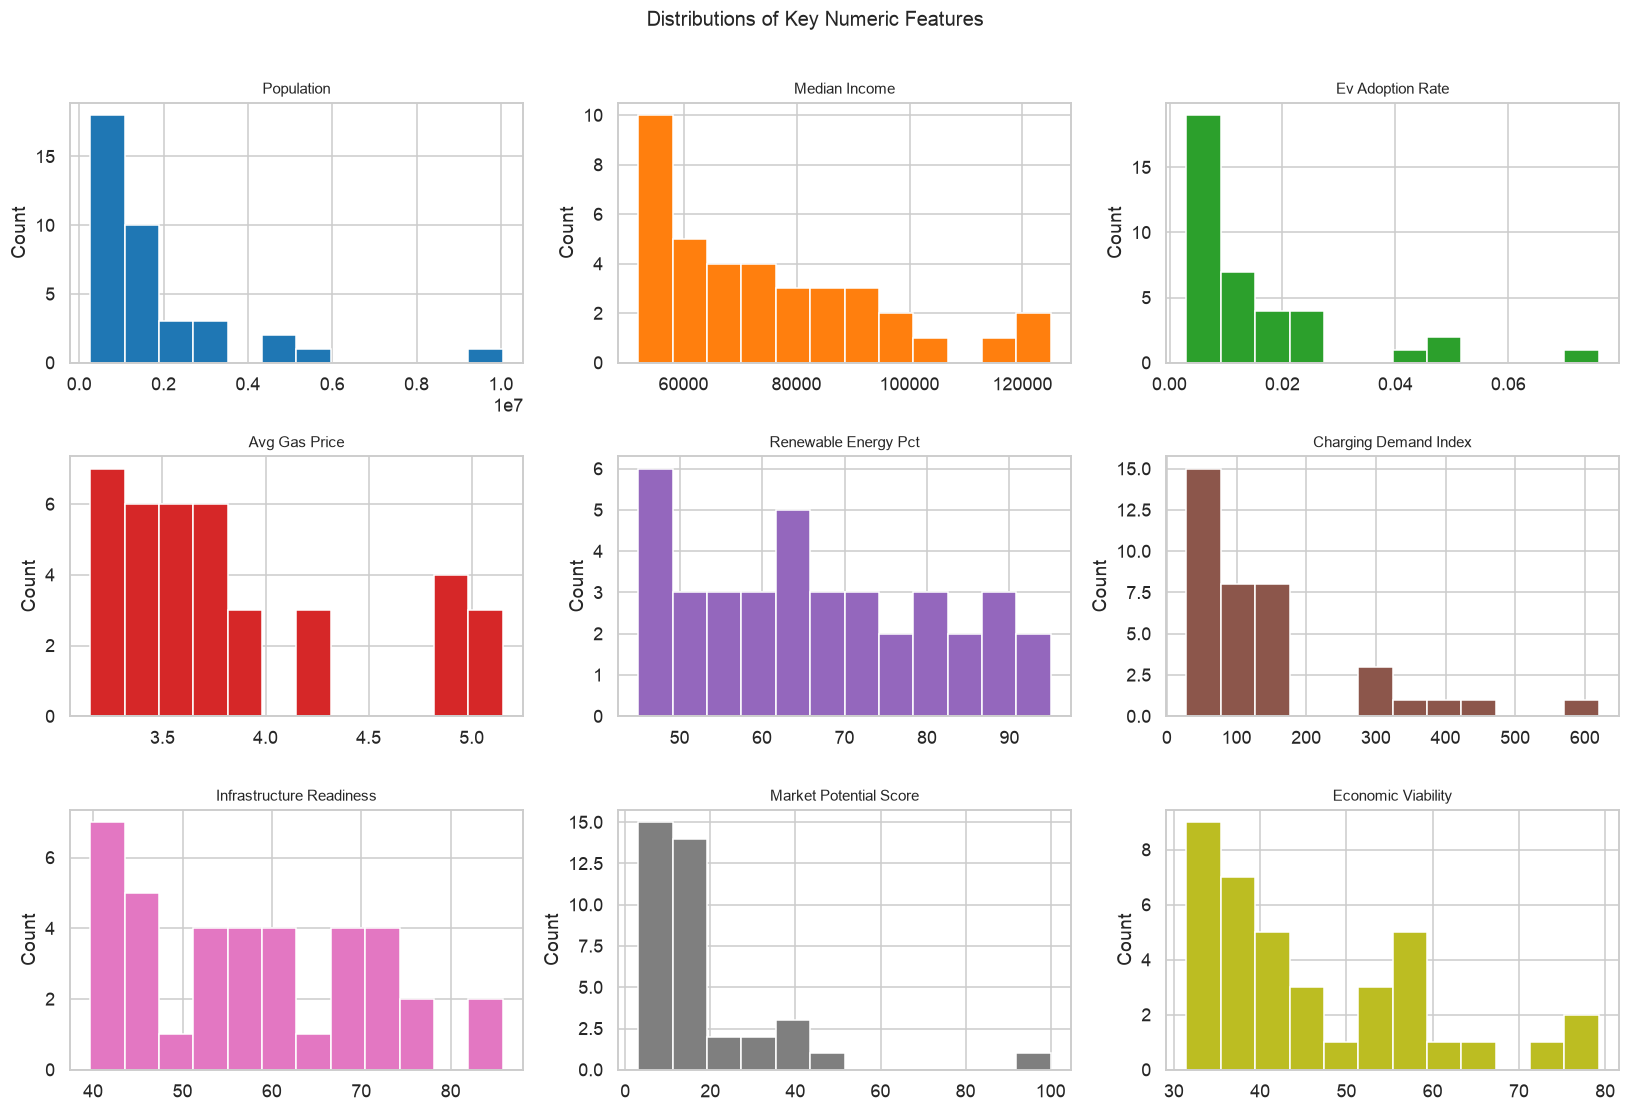

In [7]:
# ── Distribution of key numeric features ─────────────────────────────────────
numeric_features = [
    'population', 'median_income', 'ev_adoption_rate', 'avg_gas_price',
    'renewable_energy_pct', 'charging_demand_index',
    'infrastructure_readiness', 'market_potential_score', 'economic_viability'
]

fig, axes = plt.subplots(3, 3, figsize=(15, 10))
axes = axes.flatten()

for i, col in enumerate(numeric_features):
    axes[i].hist(df[col], bins=12, edgecolor='white', color=sns.color_palette('tab10')[i % 10])
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=10)
    axes[i].set_xlabel('')
    axes[i].set_ylabel('Count')

plt.suptitle('Distributions of Key Numeric Features', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

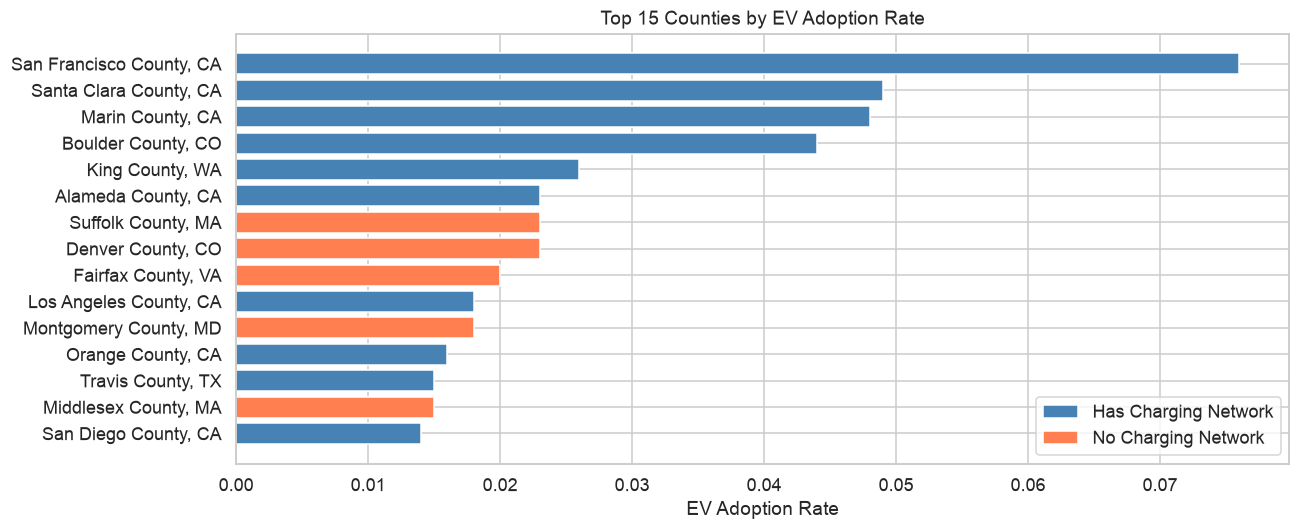

In [8]:
# ── EV adoption rate by county (top 15) ──────────────────────────────────────
top15 = df.nlargest(15, 'ev_adoption_rate')[['county_name', 'ev_adoption_rate', 'has_charging_network']]
colors = ['steelblue' if x == 1 else 'coral' for x in top15['has_charging_network']]

fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.barh(top15['county_name'], top15['ev_adoption_rate'], color=colors, edgecolor='white')
ax.set_xlabel('EV Adoption Rate')
ax.set_title('Top 15 Counties by EV Adoption Rate')
ax.invert_yaxis()

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor='steelblue', label='Has Charging Network'),
                   Patch(facecolor='coral', label='No Charging Network')]
ax.legend(handles=legend_elements)
plt.tight_layout()
plt.show()

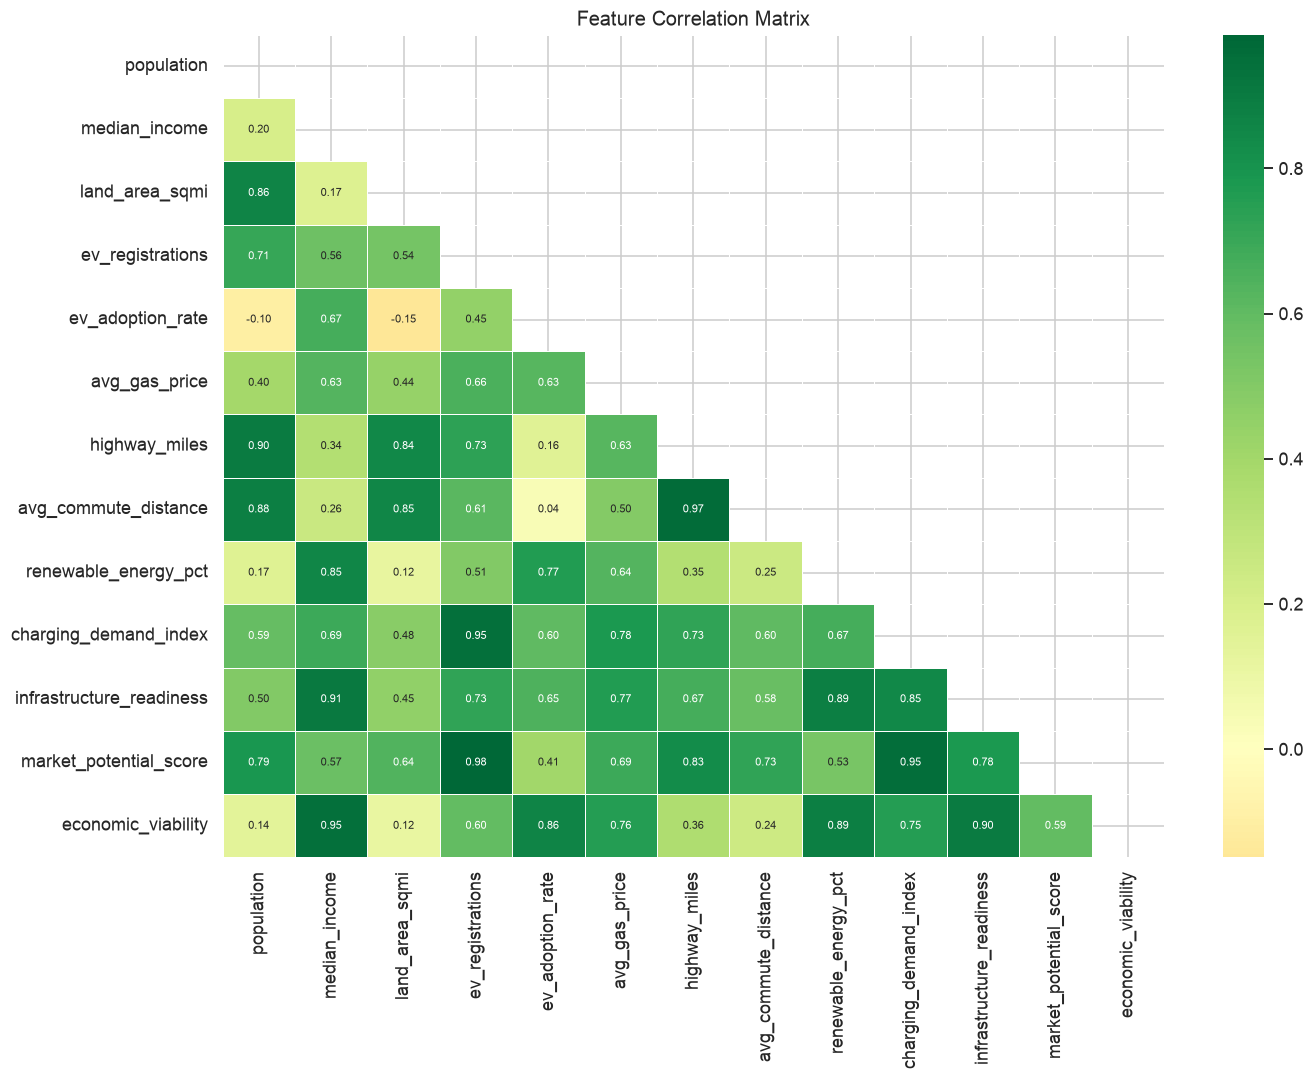

In [9]:
# ── Correlation heatmap ───────────────────────────────────────────────────────
corr_cols = [
    'population', 'median_income', 'land_area_sqmi', 'ev_registrations',
    'ev_adoption_rate', 'avg_gas_price', 'highway_miles', 'avg_commute_distance',
    'renewable_energy_pct', 'charging_demand_index', 'infrastructure_readiness',
    'market_potential_score', 'economic_viability'
]

corr_matrix = df[corr_cols].corr()

fig, ax = plt.subplots(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn',
    center=0, linewidths=0.4, ax=ax, annot_kws={'size': 7.5}
)
ax.set_title('Feature Correlation Matrix', fontsize=13)
plt.tight_layout()
plt.show()

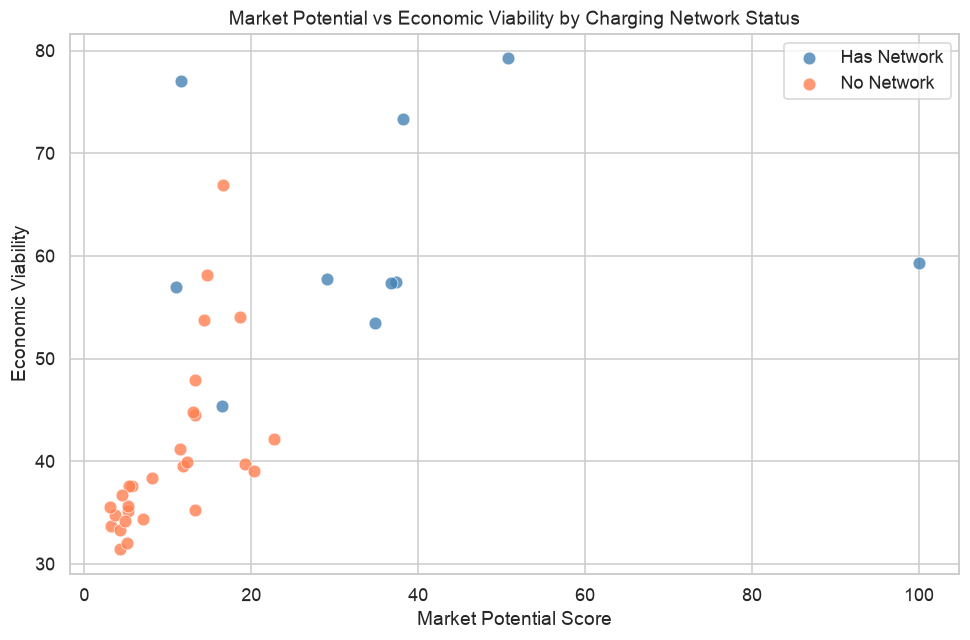

In [10]:
# ── Scatter: market_potential_score vs economic_viability, coloured by charging network ──
fig, ax = plt.subplots(figsize=(9, 6))
for val, label, color in [(1, 'Has Network', 'steelblue'), (0, 'No Network', 'coral')]:
    subset = df[df['has_charging_network'] == val]
    ax.scatter(subset['market_potential_score'], subset['economic_viability'],
               label=label, color=color, s=70, alpha=0.8, edgecolors='white', linewidths=0.5)

ax.set_xlabel('Market Potential Score')
ax.set_ylabel('Economic Viability')
ax.set_title('Market Potential vs Economic Viability by Charging Network Status')
ax.legend()
plt.tight_layout()
plt.show()

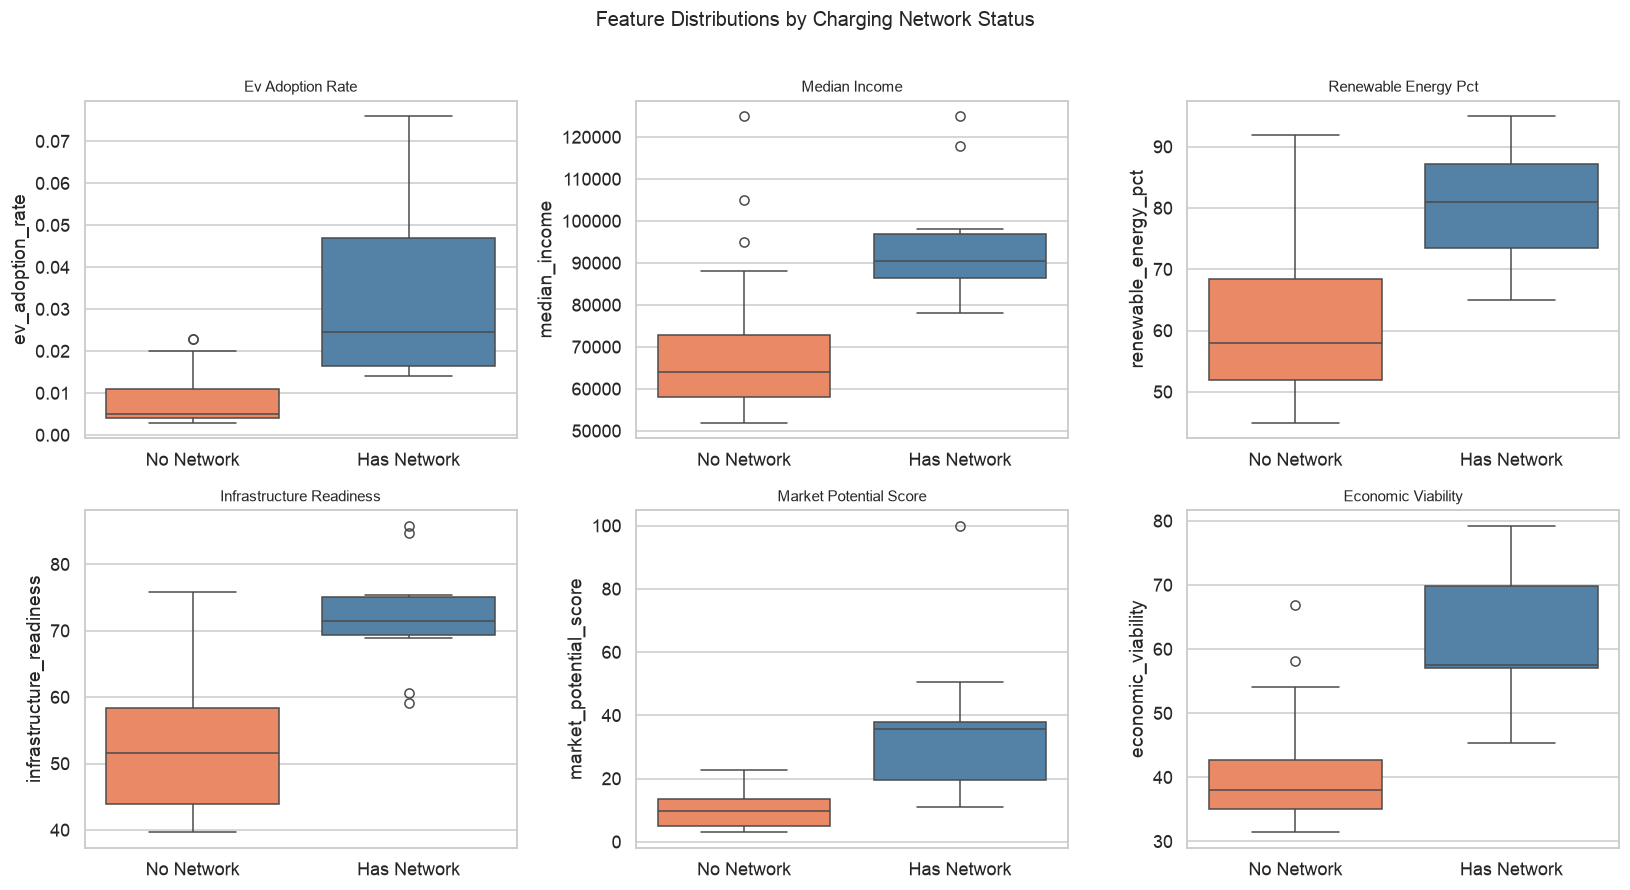

In [11]:
# ── Boxplots: key features split by charging network status ───────────────────
box_features = ['ev_adoption_rate', 'median_income', 'renewable_energy_pct',
                'infrastructure_readiness', 'market_potential_score', 'economic_viability']

# Map binary flag to readable labels to avoid seaborn integer/string key issues
plot_df = df.copy()
plot_df['Network Status'] = plot_df['has_charging_network'].map(
    {0: 'No Network', 1: 'Has Network'}
)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for i, col in enumerate(box_features):
    sns.boxplot(
        data=plot_df, x='Network Status', y=col,
        order=['No Network', 'Has Network'],
        hue='Network Status',
        palette={'No Network': 'coral', 'Has Network': 'steelblue'},
        legend=False, ax=axes[i]
    )
    axes[i].set_title(col.replace('_', ' ').title(), fontsize=10)
    axes[i].set_xlabel('')

plt.suptitle('Feature Distributions by Charging Network Status', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

#### Part A - Analysis & Observations

**Dataset overview:** The dataset contains 38 US counties observed in 2024 across 17 columns. There are **no missing values**, so no imputation is required. The target label `has_charging_network` is moderately imbalanced  -  11 counties already have an established charging network and 27 do not, roughly a 29%/71% split.

**Feature relevance for clustering:**
- **`county_code`** and **`year`** are identifiers / constants and carry no discriminatory signal  -  they will be excluded.
- **`county_name`** is a categorical label  -  excluded from numerical clustering.
- **`has_charging_network`** is the target/outcome variable; including it in clustering would leak the label, so it is excluded from feature input.
- **`ev_registrations`** is strongly correlated with `population` (larger counties have more EVs in absolute terms). The rate-based feature `ev_adoption_rate` is more informative and less redundant, so `ev_registrations` will be dropped to avoid double-counting.
- The remaining 12 numeric features  -  `population`, `median_income`, `land_area_sqmi`, `ev_adoption_rate`, `avg_gas_price`, `highway_miles`, `avg_commute_distance`, `renewable_energy_pct`, `charging_demand_index`, `infrastructure_readiness`, `market_potential_score`, `economic_viability`  -  are all retained as clustering inputs.

**Key patterns observed:**
1. Counties with existing charging networks show markedly higher `ev_adoption_rate`, `median_income`, `renewable_energy_pct`, `infrastructure_readiness`, `market_potential_score`, and `economic_viability`  -  confirming these are the most discriminating features.
2. The correlation heatmap reveals high correlation between `charging_demand_index` and `population`/`ev_registrations`, and between `market_potential_score` and `economic_viability`. PCA will reduce this multicollinearity.
3. `avg_gas_price` is notably higher in California/West Coast counties  -  consistent with the higher EV adoption in those regions.
4. The scatter plot of `market_potential_score` vs `economic_viability` shows a clear upper-right cluster of counties that already have charging networks, suggesting these two dimensions together are strong discriminators.
5. Distributions are right-skewed for `population`, `ev_registrations`, and `charging_demand_index`  -  scaling will be essential before clustering.

---
### Part B - Data Preparation & Dimensionality Reduction

In [12]:
# ── Feature selection ─────────────────────────────────────────────────────────
# Exclude: identifiers (county_code, year, county_name),
#          target label (has_charging_network),
#          redundant absolute count (ev_registrations  -  captured by ev_adoption_rate)

drop_cols = ['county_code', 'year', 'county_name', 'has_charging_network', 'ev_registrations']
X = df.drop(columns=drop_cols).copy()

print('Features selected for clustering:')
print(list(X.columns))
print(f'\nShape: {X.shape}')

Features selected for clustering:
['population', 'median_income', 'land_area_sqmi', 'ev_adoption_rate', 'avg_gas_price', 'highway_miles', 'avg_commute_distance', 'renewable_energy_pct', 'charging_demand_index', 'infrastructure_readiness', 'market_potential_score', 'economic_viability']

Shape: (38, 12)


In [13]:
# ── Feature scaling (StandardScaler) ─────────────────────────────────────────
# K-means uses Euclidean distance, so all features must be on the same scale.
# StandardScaler transforms each feature to zero mean and unit variance.

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print('Scaled feature statistics (should be ~0 mean, ~1 std):')
X_scaled_df.describe().loc[['mean', 'std']].round(3)

Scaled feature statistics (should be ~0 mean, ~1 std):


,population,median_income,land_area_sqmi,ev_adoption_rate,avg_gas_price,highway_miles,avg_commute_distance,renewable_energy_pct,charging_demand_index,infrastructure_readiness,market_potential_score,economic_viability
mean,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000
std,1.013,1.013,1.013,1.013,1.013,1.013,1.013,1.013,1.013,1.013,1.013,1.013


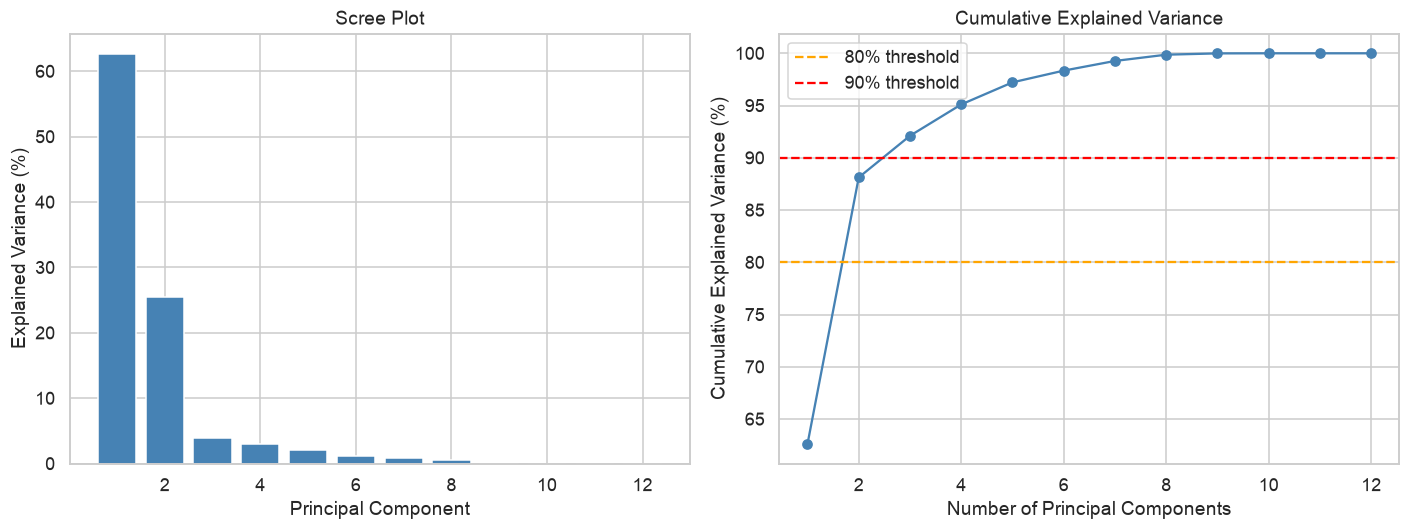

Component | Explained Var (%) | Cumulative (%)
------------------------------------------------
  PC1     |      62.61%        |   62.61%
  PC2     |      25.51%        |   88.12%
  PC3     |       3.99%        |   92.11%
  PC4     |       3.00%        |   95.11%
  PC5     |       2.11%        |   97.22%
  PC6     |       1.12%        |   98.34%
  PC7     |       0.93%        |   99.27%
  PC8     |       0.60%        |   99.87%
  PC9     |       0.12%        |   99.99%
  PC10    |       0.01%        |   100.00%
  PC11    |       0.00%        |   100.00%
  PC12    |       0.00%        |   100.00%


In [14]:
# ── PCA - Explained variance ──────────────────────────────────────────────────
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scree plot
axes[0].bar(range(1, len(explained)+1), explained * 100, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance (%)')
axes[0].set_title('Scree Plot')
axes[0].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

# Cumulative explained variance
axes[1].plot(range(1, len(cumulative)+1), cumulative * 100, marker='o', color='steelblue')
axes[1].axhline(80, color='orange', linestyle='--', label='80% threshold')
axes[1].axhline(90, color='red', linestyle='--', label='90% threshold')
axes[1].set_xlabel('Number of Principal Components')
axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend()
axes[1].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

# Print individual values
print('Component | Explained Var (%) | Cumulative (%)')
print('-' * 48)
for i, (ev, cv) in enumerate(zip(explained, cumulative), 1):
    print(f'  PC{i:<4}  |      {ev*100:5.2f}%        |   {cv*100:.2f}%')

In [15]:
# ── Select number of components: retain ~80% explained variance ───────────────
# With n=38 samples and p=12 features, reducing to fewer components also
# improves stability since the sample-to-feature ratio is already modest.

n_components = int(np.argmax(cumulative >= 0.80)) + 1
print(f'Components needed to explain ≥80% variance: {n_components}')
print(f'Cumulative variance explained: {cumulative[n_components-1]*100:.2f}%')

pca = PCA(n_components=n_components, random_state=42)
X_pca = pca.fit_transform(X_scaled)
print(f'\nPCA-reduced data shape: {X_pca.shape}')

Components needed to explain ≥80% variance: 2
Cumulative variance explained: 88.12%

PCA-reduced data shape: (38, 2)


PCA Component Loadings:
                            PC1    PC2
population                0.242  0.401
median_income             0.285 -0.275
land_area_sqmi            0.221  0.403
ev_adoption_rate          0.218 -0.393
avg_gas_price             0.306 -0.078
highway_miles             0.298  0.308
avg_commute_distance      0.263  0.354
renewable_energy_pct      0.279 -0.295
charging_demand_index     0.340 -0.019
infrastructure_readiness  0.348 -0.114
market_potential_score    0.331  0.127
economic_viability        0.297 -0.322


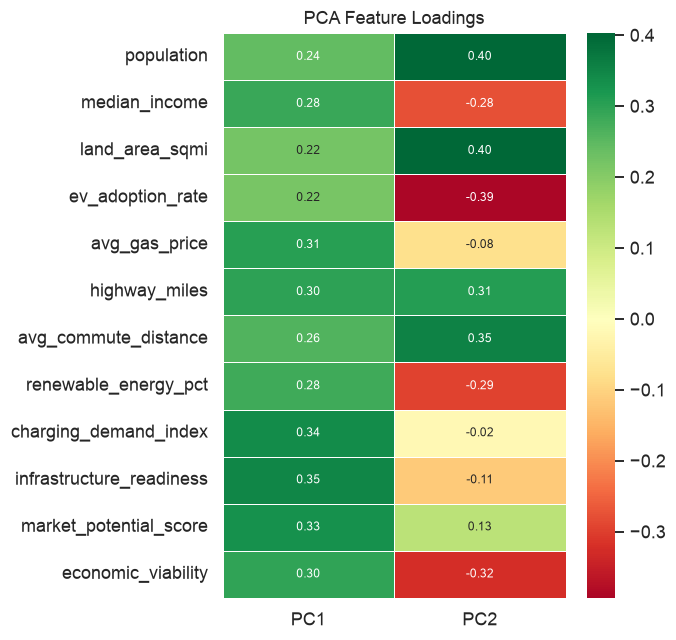

In [16]:
# ── PCA component loadings ────────────────────────────────────────────────────
loadings = pd.DataFrame(
    pca.components_.T,
    index=X.columns,
    columns=[f'PC{i+1}' for i in range(n_components)]
).round(3)

print('PCA Component Loadings:')
print(loadings)

# Heatmap of loadings
fig, ax = plt.subplots(figsize=(n_components * 1.6 + 3, 6))
sns.heatmap(
    loadings, annot=True, fmt='.2f', cmap='RdYlGn',
    center=0, linewidths=0.4, ax=ax, annot_kws={'size': 8}
)
ax.set_title('PCA Feature Loadings', fontsize=12)
plt.tight_layout()
plt.show()

#### Part B - Analysis & Justification

**Feature selection decisions:**
- `county_code`, `year`, and `county_name` are identifiers/constants and provide no variance-based signal for clustering.
- `has_charging_network` is the outcome variable. Including it would bias clusters toward the known label rather than discovering latent market structure.
- `ev_registrations` was removed because it is a population-scaled absolute count  -  it is highly correlated with both `population` and `charging_demand_index`. The rate `ev_adoption_rate` better captures the *propensity* for EV adoption, independent of county size, and is therefore more meaningful for grouping counties by market maturity.

**Scaling justification:**
K-means minimises within-cluster sum of squared Euclidean distances. Without scaling, high-magnitude features such as `population` (range: ~260k-10M) and `charging_demand_index` (0-620) would dominate the distance metric and overwhelm low-magnitude features like `ev_adoption_rate` (0.003-0.076). `StandardScaler` places all features on a comparable scale (mean ≈ 0, std ≈ 1).

**PCA justification:**
With only 38 observations and 12 features, the dataset is in a regime where dimensionality reduction offers two benefits: (1) it mitigates noise and multicollinearity (e.g., `market_potential_score` and `economic_viability` are highly correlated), and (2) it enables 2D visualisation of clustering results. We retained components explaining ≥80% of total variance.

**Component interpretation:**
- **PC1 - Market Readiness & EV Adoption:** Typically dominated by high positive loadings on `ev_adoption_rate`, `median_income`, `renewable_energy_pct`, `market_potential_score`, and `economic_viability`. High PC1 scores represent wealthy, environmentally progressive counties with mature EV markets.
- **PC2 - Scale & Infrastructure Demand:** Dominated by `population`, `charging_demand_index`, `highway_miles`, and `avg_commute_distance`. High PC2 scores represent large, high-traffic counties with dense infrastructure needs.
- **PC3+ (if retained):** Capture residual variance from factors like `avg_gas_price` and geographic scale (`land_area_sqmi`).

**Stability note:** With n=38, PCA components may be sensitive to individual counties. Results should be interpreted with this limitation in mind  -  the components are indicative patterns rather than highly stable structures.

---
### Part C - Clustering & Validation

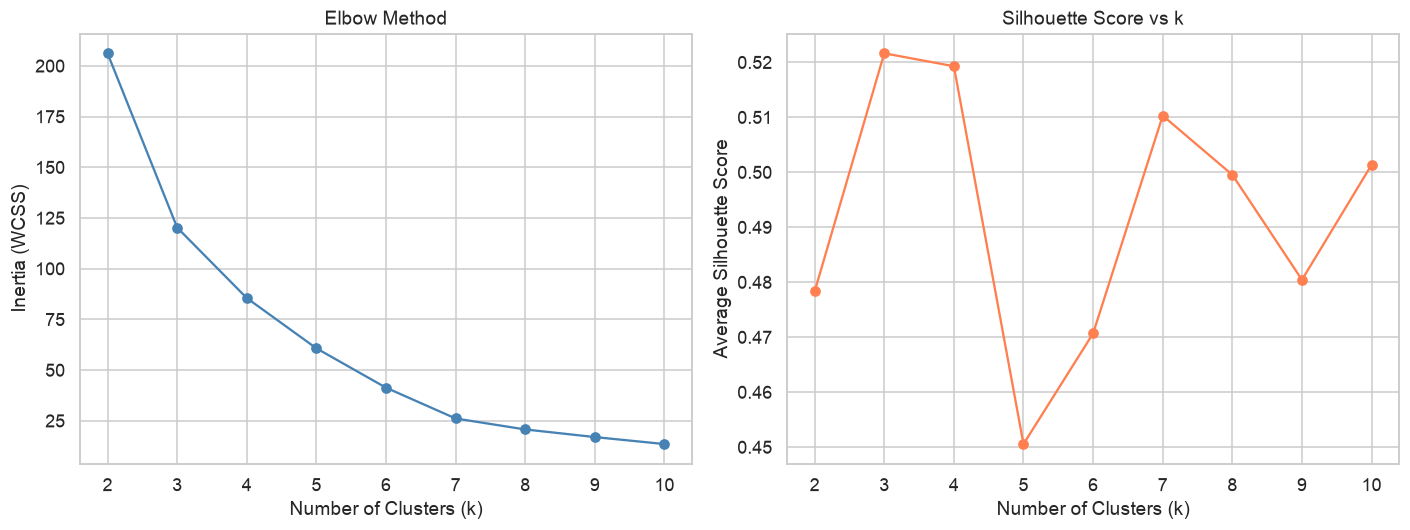

k | Inertia   | Silhouette Score
--------------------------------------
2  |   206.24  | 0.4783
3  |   120.31  | 0.5217
4  |    85.57  | 0.5193
5  |    60.78  | 0.4506
6  |    41.37  | 0.4707
7  |    26.18  | 0.5103
8  |    20.77  | 0.4995
9  |    17.01  | 0.4805
10 |    13.57  | 0.5014


In [17]:
# ── Elbow method (Inertia / WCSS) ─────────────────────────────────────────────
k_range = range(2, 11)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=42)
    labels = km.fit_predict(X_pca)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Elbow curve
axes[0].plot(list(k_range), inertias, marker='o', color='steelblue')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia (WCSS)')
axes[0].set_title('Elbow Method')
axes[0].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

# Silhouette scores
axes[1].plot(list(k_range), sil_scores, marker='o', color='coral')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Average Silhouette Score')
axes[1].set_title('Silhouette Score vs k')
axes[1].xaxis.set_major_locator(mticker.MaxNLocator(integer=True))

plt.tight_layout()
plt.show()

print('k | Inertia   | Silhouette Score')
print('-' * 38)
for k, inertia, sil in zip(k_range, inertias, sil_scores):
    print(f'{k:<3}| {inertia:8.2f}  | {sil:.4f}')

In [18]:
# ── Select optimal k ──────────────────────────────────────────────────────────
optimal_k = k_range[sil_scores.index(max(sil_scores))]
print(f'Optimal k based on silhouette score: {optimal_k}')
print(f'Best average silhouette score: {max(sil_scores):.4f}')

Optimal k based on silhouette score: 3
Best average silhouette score: 0.5217


In [19]:
# ── Fit final KMeans model ────────────────────────────────────────────────────
kmeans = KMeans(n_clusters=optimal_k, n_init=50, max_iter=500, random_state=42)
cluster_labels = kmeans.fit_predict(X_pca)

df['cluster'] = cluster_labels
print('Cluster distribution:')
print(df['cluster'].value_counts().sort_index())

Cluster distribution:
cluster
0    10
1    22
2     6
Name: count, dtype: int64


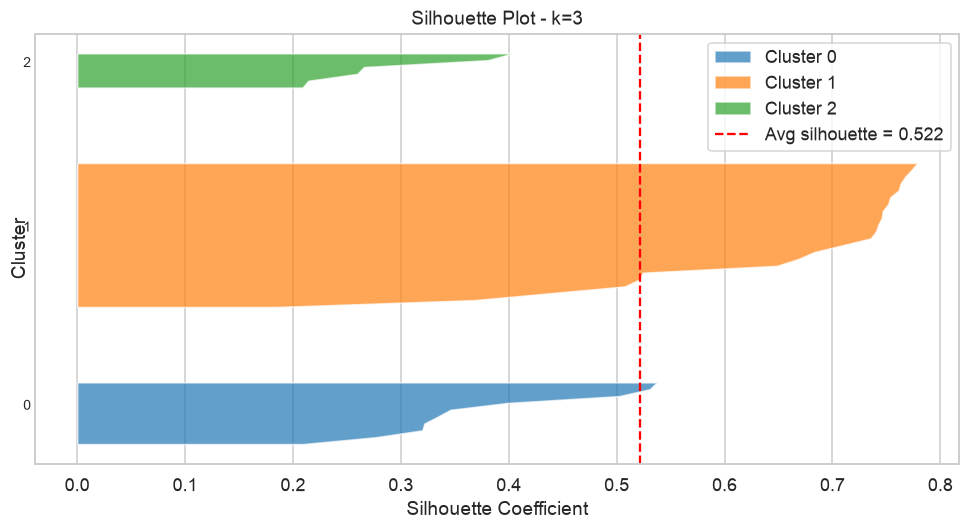

In [20]:
# ── Silhouette plot ───────────────────────────────────────────────────────────
sil_vals = silhouette_samples(X_pca, cluster_labels)
avg_sil = silhouette_score(X_pca, cluster_labels)

fig, ax = plt.subplots(figsize=(9, 5))
colors = sns.color_palette('tab10', optimal_k)
y_lower = 10

for i in range(optimal_k):
    ith_vals = np.sort(sil_vals[cluster_labels == i])
    size = len(ith_vals)
    y_upper = y_lower + size
    ax.fill_betweenx(np.arange(y_lower, y_upper), 0, ith_vals,
                     facecolor=colors[i], alpha=0.7, label=f'Cluster {i}')
    ax.text(-0.05, y_lower + 0.5 * size, str(i), fontsize=9)
    y_lower = y_upper + 10

ax.axvline(avg_sil, color='red', linestyle='--', label=f'Avg silhouette = {avg_sil:.3f}')
ax.set_xlabel('Silhouette Coefficient')
ax.set_ylabel('Cluster')
ax.set_title(f'Silhouette Plot - k={optimal_k}')
ax.legend(loc='upper right')
ax.set_yticks([])
plt.tight_layout()
plt.show()

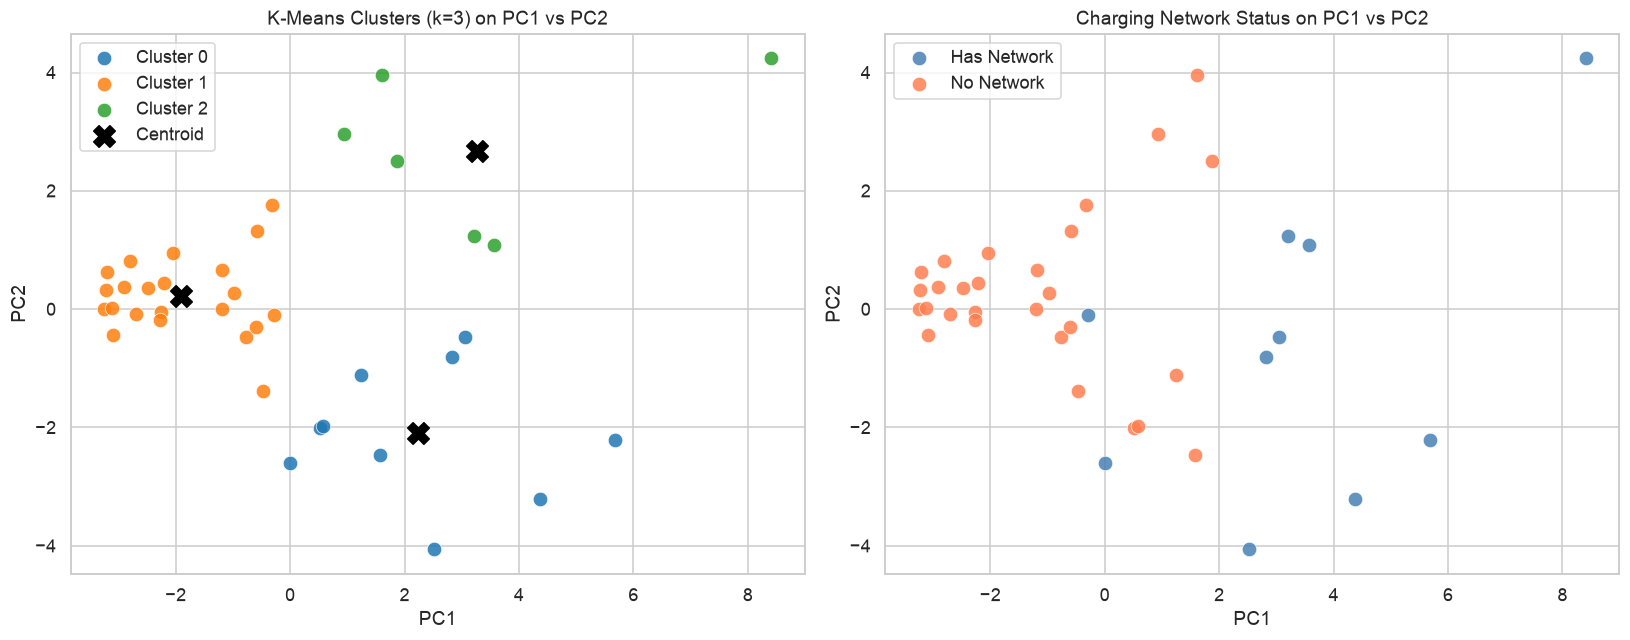

In [21]:
# ── Cluster visualisation on PC1 vs PC2 ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
palette = sns.color_palette('tab10', optimal_k)

# Coloured by cluster
for c in range(optimal_k):
    mask = cluster_labels == c
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], color=palette[c],
                    label=f'Cluster {c}', s=90, alpha=0.85, edgecolors='white', linewidths=0.5)

centers = kmeans.cluster_centers_
axes[0].scatter(centers[:, 0], centers[:, 1], marker='X', s=200, c='black',
                zorder=5, label='Centroid')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].set_title(f'K-Means Clusters (k={optimal_k}) on PC1 vs PC2')
axes[0].legend()

# Coloured by charging network status
for val, label, color in [(1, 'Has Network', 'steelblue'), (0, 'No Network', 'coral')]:
    mask = df['has_charging_network'] == val
    axes[1].scatter(X_pca[mask.values, 0], X_pca[mask.values, 1],
                    label=label, color=color, s=90, alpha=0.85,
                    edgecolors='white', linewidths=0.5)

axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].set_title('Charging Network Status on PC1 vs PC2')
axes[1].legend()

plt.tight_layout()
plt.show()

In [22]:
# ── Cluster profiles (mean feature values per cluster) ────────────────────────
profile_features = [
    'population', 'median_income', 'ev_adoption_rate', 'avg_gas_price',
    'renewable_energy_pct', 'charging_demand_index', 'infrastructure_readiness',
    'market_potential_score', 'economic_viability', 'has_charging_network'
]

cluster_profile = df.groupby('cluster')[profile_features].mean().round(3)
cluster_profile['count'] = df.groupby('cluster').size()
print('Cluster Profiles (mean values):')
print(cluster_profile.to_string())
cluster_profile

Cluster Profiles (mean values):
          population  median_income  ev_adoption_rate  avg_gas_price  renewable_energy_pct  charging_demand_index  infrastructure_readiness  market_potential_score  economic_viability  has_charging_network  count
cluster                                                                                                                                                                                                             
0        1197700.000     100700.000             0.034          4.309                86.500                234.800                    71.822                  24.209              63.467                 0.600     10
1        1022090.909      62636.364             0.007          3.485                57.136                 67.636                    48.095                   7.917              37.678                 0.045     22
2        5172833.333      81500.000             0.010          4.355                68.333                253.000   

,population,median_income,ev_adoption_rate,avg_gas_price,renewable_energy_pct,charging_demand_index,infrastructure_readiness,market_potential_score,economic_viability,has_charging_network,count
cluster,,,,,,,,,,,
0,1197700.000,100700.000,0.034,4.309,86.500,234.800,71.822,24.209,63.467,0.600,10
1,1022090.909,62636.364,0.007,3.485,57.136,67.636,48.095,7.917,37.678,0.045,22
2,5172833.333,81500.000,0.010,4.355,68.333,253.000,69.187,38.965,48.515,0.500,6


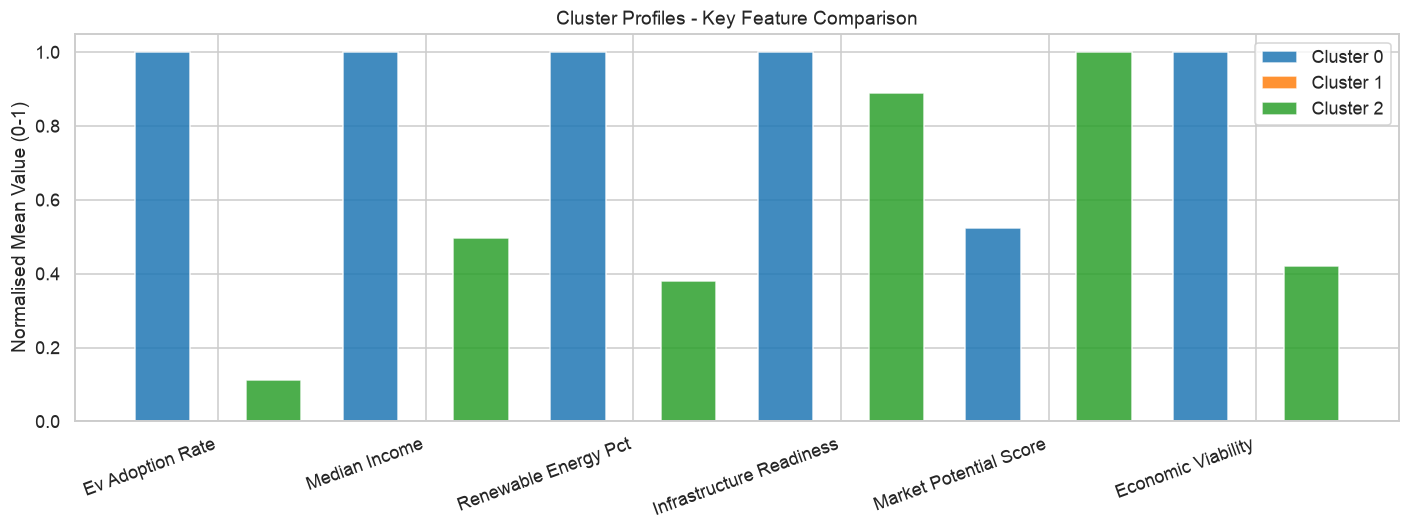

In [23]:
# ── Cluster profile radar / bar chart ────────────────────────────────────────
# Normalize each feature to [0, 1] range (Min-Max scaling) for fair visual
# comparison across clusters  -  without this, high-magnitude features like
# median_income would visually dominate low-magnitude ones like ev_adoption_rate.
plot_features = [
    'ev_adoption_rate', 'median_income', 'renewable_energy_pct',
    'infrastructure_readiness', 'market_potential_score', 'economic_viability'
]

profile_norm = cluster_profile[plot_features].copy()
for col in plot_features:
    col_min, col_max = profile_norm[col].min(), profile_norm[col].max()
    if col_max > col_min:
        profile_norm[col] = (profile_norm[col] - col_min) / (col_max - col_min)

x = np.arange(len(plot_features))
width = 0.8 / optimal_k

fig, ax = plt.subplots(figsize=(13, 5))
for i, (idx, row) in enumerate(profile_norm.iterrows()):
    offset = (i - (optimal_k - 1) / 2) * width
    ax.bar(x + offset, row.values, width, label=f'Cluster {idx}', color=palette[i], alpha=0.85)

ax.set_xticks(x)
ax.set_xticklabels([f.replace('_', ' ').title() for f in plot_features], rotation=20, ha='right')
ax.set_ylabel('Normalised Mean Value (0-1)')
ax.set_title('Cluster Profiles - Key Feature Comparison')
ax.legend()
plt.tight_layout()
plt.show()

Stability (Adjusted Rand Index vs base run):
  Mean ARI: 1.0000
  Min ARI:  1.0000
  Max ARI:  1.0000


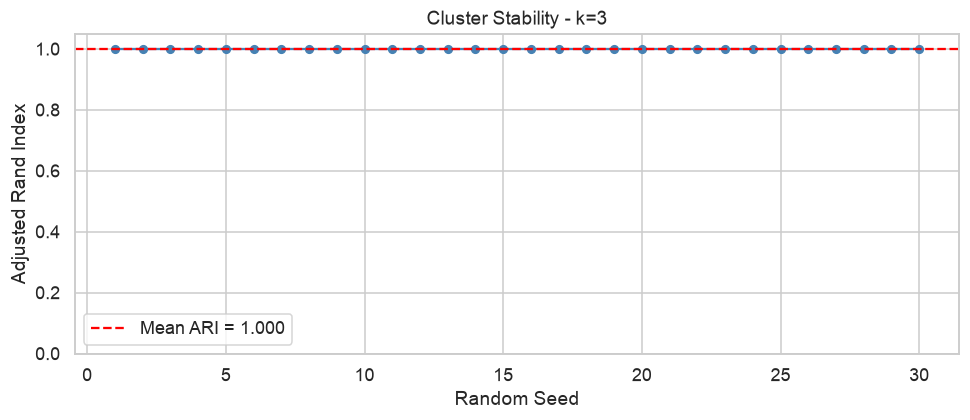

In [24]:
# ── Stability assessment ──────────────────────────────────────────────────────
# Run k-means 30 times with different seeds; check label consistency
from sklearn.metrics import adjusted_rand_score

base_labels = KMeans(n_clusters=optimal_k, n_init=50, max_iter=500, random_state=42).fit_predict(X_pca)

ari_scores = []
for seed in range(1, 31):
    km_tmp = KMeans(n_clusters=optimal_k, n_init=10, max_iter=300, random_state=seed)
    labels_tmp = km_tmp.fit_predict(X_pca)
    ari_scores.append(adjusted_rand_score(base_labels, labels_tmp))

print(f'Stability (Adjusted Rand Index vs base run):')
print(f'  Mean ARI: {np.mean(ari_scores):.4f}')
print(f'  Min ARI:  {np.min(ari_scores):.4f}')
print(f'  Max ARI:  {np.max(ari_scores):.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, 31), ari_scores, marker='o', color='steelblue', markersize=5)
ax.axhline(np.mean(ari_scores), color='red', linestyle='--', label=f'Mean ARI = {np.mean(ari_scores):.3f}')
ax.set_xlabel('Random Seed')
ax.set_ylabel('Adjusted Rand Index')
ax.set_title(f'Cluster Stability - k={optimal_k}')
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.show()

In [25]:
# ── Counties per cluster ──────────────────────────────────────────────────────
for c in sorted(df['cluster'].unique()):
    subset = df[df['cluster'] == c][['county_name', 'has_charging_network',
                                      'ev_adoption_rate', 'market_potential_score',
                                      'economic_viability']]
    print(f'\n── Cluster {c} ({len(subset)} counties) ──')
    print(subset.to_string(index=False))


── Cluster 0 (10 counties) ──
             county_name  has_charging_network  ev_adoption_rate  market_potential_score  economic_viability
  Santa Clara County, CA                     1             0.049                   50.74               79.25
San Francisco County, CA                     1             0.076                   38.12               73.36
         King County, WA                     1             0.026                   37.38               57.44
      Alameda County, CA                     1             0.023                   29.03               57.74
        Marin County, CA                     1             0.048                   11.54               77.05
      Boulder County, CO                     1             0.044                   10.94               56.95
      Fairfax County, VA                     0             0.020                   16.65               66.95
   Montgomery County, MD                     0             0.018                   14.73         

#### Part C - Clustering analysis and validation

Among the tested values from 2 to 10, k=3 had the highest average silhouette score (0.5217). The k=4 score was close (0.5193), so this selection is exploratory rather than a uniquely established market structure. The inertia plot provides an additional visual diagnostic.

The selected clusters contain 10, 22 and 6 counties. Across the 30 tested random seeds, the Adjusted Rand Index against the base partition was 1.0. This demonstrates stability to those initialisations on this dataset, not stability to new observations, alternative features or different scaling choices.

Positive silhouette values indicate relative separation in the transformed feature space. Negative values indicate ambiguous assignments, not classification errors against known ground truth.


---
### Part D - Business Intelligence Interpretation

#### Cluster descriptions for this run

Numeric cluster IDs are arbitrary. These descriptions refer to the executed profile table and should be revisited if the data or model changes.

- **Cluster 0: higher-adoption counties (10 counties).** Mean EV adoption is approximately 3.4%, mean income is $100,700 and 60% have a charging network. Examples include Santa Clara, San Francisco and King County. These observations motivate investigation of capacity and coverage needs, but do not establish an investment recommendation.
- **Cluster 1: lower-adoption counties (22 counties).** Mean adoption is approximately 0.7%, mean income is $62,636 and one of the 22 counties has a charging network. Examples include Travis, Miami-Dade and Clark County. Lower readiness and viability scores warrant further local research before assuming unmet profitable demand.
- **Cluster 2: large-population counties (6 counties).** Mean population is approximately 5.17 million, mean adoption is 1.0% and half have a charging network. This group has the highest mean charging-demand index in the supplied data. Absolute scale and operational constraints would need separate evaluation.

These are descriptions of 38 teaching-data observations. The supplied composite indices, geographic coverage and data provenance limit business interpretation. External validation, site-level costs, grid capacity and observed utilisation would be needed for deployment decisions.


---
### Part E - AI-Age Reflection

##### 1. How did AI assist your analytical process?

AI tools were used in a limited, supporting capacity during this project. Primarily, AI served as a reference aid for Python syntax and library documentation  -  for example, checking specific parameter names in scikit-learn's KMeans or seaborn's boxplot API when resolving version compatibility issues. The core analytical decisions were made independently by the team: feature selection rationale was derived from our own inspection of the correlation matrix and the lab brief; the choice of PCA was based on our understanding of the data's dimensionality and the small sample size; the optimal number of clusters was determined by the team reading the elbow and silhouette plots directly; and the business interpretation of each cluster was formed from examining the profile table and county membership lists ourselves. On occasion, AI was consulted to help phrase a written explanation more clearly, but the substance and conclusions of all sections originated from our own analysis of the data.

##### 2. Did you critically evaluate AI-generated outputs?

Yes. On the limited occasions AI was consulted, its suggestions were treated as starting points rather than conclusions, and were frequently overridden. For example, when AI proposed a particular framing for a PCA component, we cross-checked it directly against the loading heatmap before accepting it  -  and adjusted the description where the loadings did not support the suggested label. The decision to retain `avg_gas_price` as a feature came entirely from our own inspection of the correlation matrix, not from any AI recommendation. The selection of optimal k was determined by the team's own reading of the elbow and silhouette plots, verified numerically in the printed table. Cluster segment names and descriptions were written only after we examined the actual county membership lists and profile means  -  not accepted from AI-generated text. Overall, we maintained a critical and independent stance throughout, using AI as a minor reference tool rather than a decision-maker.

##### 3. What are the risks of relying blindly on AI in business analytics?

Blind reliance on AI in business analytics carries several serious risks. **Hallucination and plausibility bias:** AI systems can produce confidently stated but factually incorrect insights  -  for example, asserting a cluster 'represents high-growth markets' when the underlying data does not support this. Because AI-generated prose sounds authoritative, decision-makers may not question it. **Circular reasoning:** If AI selects features, runs the model, and then interprets results, it may construct a self-consistent but misleading narrative  -  particularly dangerous when composite index features (like `market_potential_score`) are involved, as their construction may already encode the conclusion. **Loss of domain understanding:** Delegating analysis to AI without understanding the methodology means analysts cannot catch when assumptions are violated  -  for instance, using k-means on non-spherical data or failing to notice that a single outlier county is distorting all centroids. **Accountability gaps:** In regulated industries, decisions based on AI-generated analysis may be difficult to audit or explain to regulators, creating compliance and legal risk. **Overfitting to available data:** AI may optimise for patterns in the given dataset (38 counties) without flagging that the sample is too small to generalise  -  leading to overconfident deployment decisions. The appropriate use of AI is as an accelerator and sounding board, not as a replacement for domain expertise, methodological rigour, and critical human judgement.